# Arshia Goshtasbi
## Machine Learning, Homework 6: MLPs in PyTorch

## Part 1: Build the Dataset and DataLoader

**Explanation:**  
In this part, we load the MNIST dataset and prepare it for training. We:
1. Define transformations to convert images to tensors and normalize them.
2. Download and load the training and test datasets.
3. Wrap them in DataLoader objects for batching and shuffling.

Fill in the missing pieces marked with `# TODO` to complete the code.

🚀 **Exercise Summary: Building an MLP for MNIST Digit Classification**

In this exercise, we'll implement a **Multilayer Perceptron (MLP)** using **PyTorch** to classify handwritten digits from the **MNIST dataset**. This task will help you understand the fundamentals of neural networks and their application in image classification.

📚 **Dataset Overview:**
- **Name:** MNIST
- **Description:** 70,000 grayscale images of handwritten digits (28x28 pixels)
- **Classes:** 10 (digits 0 through 9)
- **Split:** 60,000 training images and 10,000 test images

🧠 **Model Architecture:**
- **Input Layer:** 784 units (28x28 pixels flattened)
- **Hidden Layer 1:** 256 units with ReLU activation
- **Hidden Layer 2:** 128 units with ReLU activation
- **Output Layer:** 10 units with Softmax activation (one for each digit class)

🔄 **Training Process:**
1. **Data Loading:** Utilize PyTorch's `torchvision.datasets` to load and preprocess the MNIST dataset.
2. **Model Definition:** Construct the MLP model with two hidden layers using `nn.Module`.
3. **Loss Function:** Use `nn.CrossEntropyLoss` to measure the discrepancy between predicted and actual labels.
4. **Optimizer:** Apply `torch.optim.Adam` for efficient training.
5. **Training Loop:** Iterate over the dataset for multiple epochs, updating model weights to minimize loss.
6. **Evaluation:** Assess the model's performance on the test set by calculating accuracy.

🎯 **Learning Objectives:**
- Understand the structure and function of a multilayer perceptron.
- Gain experience in data preprocessing and model training using PyTorch.
- Learn to evaluate model performance and interpret results.






In [1]:
import torch
import torchvision
from torchvision import transforms

# Define the transformations to apply to the data
# TODO: Create a Compose pipeline with ToTensor() and Normalize((0.5,), (0.5,))
transform = transforms.Compose([
    # TODO
    transforms.ToTensor(),  # Convert images to tensors
    transforms.Normalize((0.5,), (0.5,))  # Normalize with mean 0.5 and std 0.5
])

# Load the MNIST dataset
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Create the data loaders
batch_size = 64
# TODO: Replace None with the correct dataset
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("DataLoaders ready!")

DataLoaders ready!


## Part 2: Visualize Samples

**Explanation:**  
Visualizing data helps us understand what our model will see. We select random samples and plot them in a 4×4 grid.

Complete the code by filling in the TODOs.

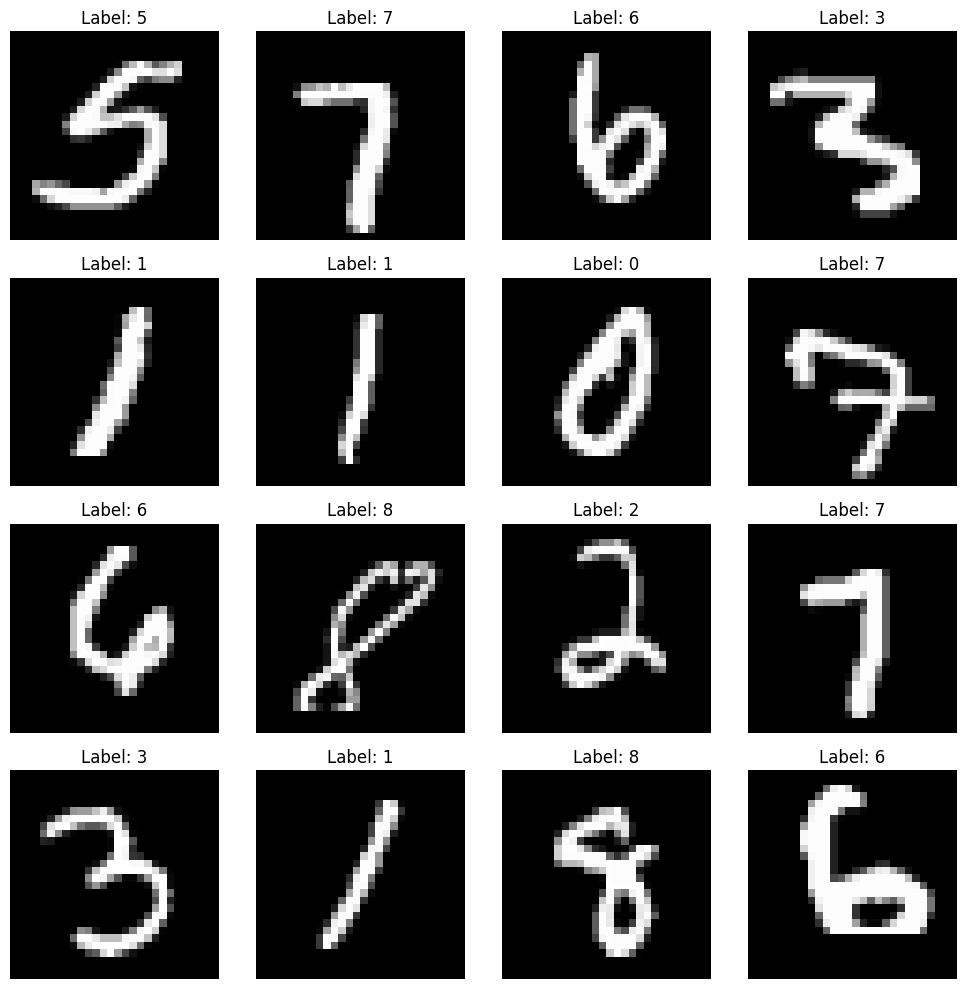

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Get 16 random indices
indices = np.random.choice(len(train_dataset), size=16, replace=False)

# TODO: Retrieve images and labels using these indices
images = [train_dataset[i][0] for i in indices]  # Get image tensor
labels = [train_dataset[i][1] for i in indices]  # Get label

# Create a figure with 4x4 subplots
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')  # TODO: image tensor
    ax.set_title(f"Label: {labels[i]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

## Part 3: Build an MLP Model

**Explanation:**  
We create a simple feedforward neural network (MLP) with one hidden layer:
- Flatten the 28×28 images into vectors.
- Apply a linear layer, ReLU activation, and a final linear layer to produce class scores.

Fill in any missing code.


In [3]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size=28*28, hidden_size=128, num_classes=10):
        super(MLP, self).__init__()
        # TODO: Define the first fully connected layer
        self.fc1 = nn.Linear(input_size, hidden_size)

        self.relu = nn.ReLU()

        # TODO: Define the second fully connected layer
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # TODO: Flatten the input tensor to match input_size
        x = x.view(x.size(0), -1)
        y = self.fc1(x)
        y = self.relu(y)
        y = self.fc2(y)

        return y

# TODO: Instantiate the model with specified parameters
model = MLP(input_size=28*28, hidden_size=128, num_classes=10)
# TODO: Create a sample input tensor
x = torch.randn(1, 1, 28, 28)  # (batch_size=1, channels=1, height=28, width=28)print(model)
print(model(x).shape)

# TODO: Calculate and print the total number of parameters
num_params = sum(p.numel() for p in model.parameters())
print(f"Number of parameters: {num_params:,}")


torch.Size([1, 10])
Number of parameters: 101,770


In [4]:
# TODO: Determine the appropriate device (CPU or GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# TODO: Move the model to the device
model.to(device)
# TODO: Define the loss function (cross-entropy for classification)
criterion = nn.CrossEntropyLoss()
# TODO: Initialize the optimizer (Adam with learning rate 0.001)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Part 5: Train the Model

**Explanation:**  
We loop over epochs and batches, performing:
1. Forward pass to compute outputs and loss.
2. Backward pass to compute gradients.
3. Optimizer step to update weights.

Insert the appropriate code where indicated.

In [5]:
from tqdm import tqdm

# TODO: Define the number of epochs
num_epochs = 5  # Reasonable for MNIST

# Set the model to training mode
model.train()

# TODO: Iterate over epochs
for epoch in tqdm(range(num_epochs)):
    total_loss = 0

    # TODO: Iterate over training data
    for images, labels in train_loader:
        # TODO: Move data to the appropriate device
        images, labels = images.to(device), labels.to(device)
        # TODO: Forward pass through the model
        outputs = model(images)
        # TODO: Compute the loss
        loss = criterion(outputs, labels)
        # TODO: Backward pass and optimization
        optimizer.zero_grad()  # Clear gradients
        loss.backward()  # Compute gradients
        optimizer.step()  # Update weights

        # Accumulate the total loss
        total_loss += loss.item()

    # Calculate the average loss for the epoch
    avg_loss = total_loss / len(train_loader)

    # TODO: Print the average loss for the epoch
    print(f"Epoch: {epoch+1}, Loss: {avg_loss:.4f}")


 20%|██        | 1/5 [00:13<00:54, 13.65s/it]

Epoch: 1, Loss: 0.3825


 40%|████      | 2/5 [00:35<00:56, 18.74s/it]

Epoch: 2, Loss: 0.2017


 60%|██████    | 3/5 [00:48<00:32, 16.02s/it]

Epoch: 3, Loss: 0.1460


 80%|████████  | 4/5 [01:01<00:14, 14.75s/it]

Epoch: 4, Loss: 0.1174


100%|██████████| 5/5 [01:14<00:00, 14.86s/it]

Epoch: 5, Loss: 0.0996


## Part 6: Predict on Sample Images

**Explanation:**  
We set the model to evaluation mode, pick a random test sample, and display the model's prediction alongside the true label.

In [6]:
# --- Evaluation Loop: Test Accuracy ---
model.eval()  # Set model to evaluation mode

correct = 0
total = 0

# TODO: Implement the loop to:
# 1. Iterate over the test dataset (`test_loader`).
# 2. Move images and labels to the correct device (`.to(device)`).
# 3. Perform a forward pass to get model outputs.
# 4. Extract predicted classes using `torch.max`.
# 5. Accumulate total samples and correct predictions.

# Iterate over the test dataset
for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)  # Move to device
    outputs = model(images)  # Forward pass
    _, predicted = torch.max(outputs, 1)  # Get predicted classes
    total += labels.size(0)  # Increment total samples
    correct += (predicted == labels).sum().item()  # Increment correct predictions
# --- End of TODO ---


accuracy = correct / total if total > 0 else 0
print(f"Test Accuracy: {accuracy:.4f}")


Test Accuracy: 0.9663


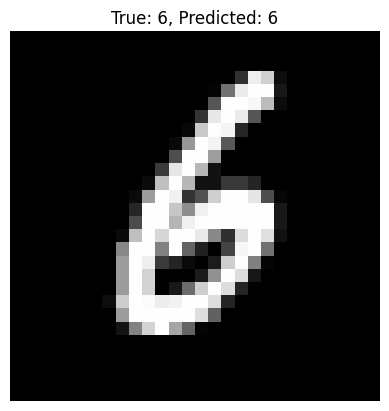

In [7]:
import random
import matplotlib.pyplot as plt

model.eval()
random_index = random.randint(0, len(test_dataset) - 1)
image, label = test_dataset[random_index]

# TODO: Move image to device
image = image.to(device)

# Forward pass and get predicted class
output = model(image.unsqueeze(0))
_, predicted_label = torch.max(output, 1)

# Display
image_np = image.cpu().numpy()
plt.imshow(image_np.squeeze(), cmap='gray')
plt.title(f"True: {label}, Predicted: {predicted_label.item()}")
plt.axis('off')
plt.show()

### **Part2**




## **Exercise: Build an MLP for CIFAR-10 Classification**

🚀 **Exercise Summary: Building a Perceptron for CIFAR-10 Classification**

In this exercise, we will implement a simple neural network model called a **Perceptron** using **PyTorch** to classify images from the **CIFAR-10 dataset**. The objective is to understand the structure and training of a basic neural network on a standard image dataset.

📦 **Dataset Overview:**
- Dataset: CIFAR-10
- Image Size: 32x32 pixels, 3 channels (RGB)
- Classes: 10 (e.g., airplane, car, bird, cat, etc.)
- Split: 50,000 training images and 10,000 test images

🔥 **Exercise Structure:**
1. **Data Preparation:**
   - Load CIFAR-10 dataset using `torchvision.datasets`.
   - Apply transformations to convert images to tensors and normalize pixel values.

2. **Model Implementation:**
   - Define a single-layer perceptron model.
   - Input Layer: 3072 units (32 × 32 × 3 pixels flattened).
   - Output Layer: 10 units (one for each class).

3. **Training Process:**
   - Implement a training loop for multiple epochs.
   - Calculate loss using Cross-Entropy Loss.
   - Optimize using SGD.

4. **Evaluation:**
   - Assess model performance using test data.
   - Calculate accuracy by comparing predicted labels to actual labels.

🎯 **Learning Outcomes:**
- Understand the structure of a perceptron model.
- Implement data preprocessing and batching for CIFAR-10.
- Apply forward propagation, loss calculation, and backpropagation.
- Analyze model performance and identify potential improvements.




In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
import numpy as np

## Exploring CIFAR10 dataset images

## **Load the CIFAR-10 dataset and apply necessary transformations.**

In [9]:
transform = transforms.ToTensor()

In [10]:
data_path = '../data_cifar/'
cifar10_train = datasets.CIFAR10(data_path, train=True, download=True, transform=transform)
cifar10_test = datasets.CIFAR10(data_path, train=False, download=True, transform=transform)

In [11]:
print("Training: ", len(cifar10_train))
print("Testing: ", len(cifar10_test))

Training:  50000
Testing:  10000


In [12]:
type(cifar10_train)

torchvision.datasets.cifar.CIFAR10

In [13]:
type(cifar10_test)

torchvision.datasets.cifar.CIFAR10

In [14]:
type(cifar10_train[0])

tuple

In [15]:
image, label = cifar10_train[0]
type(image)

torch.Tensor

In [16]:
image.shape

torch.Size([3, 32, 32])

In [17]:
classes = cifar10_train.classes
print (classes)
print(label)
print(classes[label])

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
6
frog


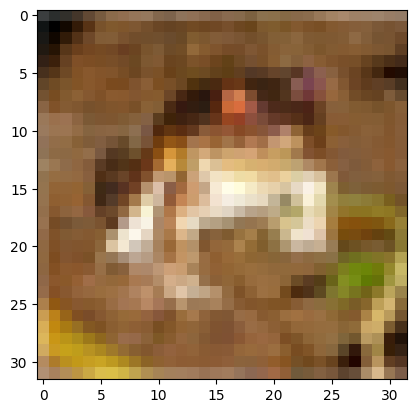

In [18]:
plt.imshow(image.permute(1, 2, 0))

In [19]:
torch.manual_seed(80)
train_loader = DataLoader(cifar10_train, batch_size=100, shuffle=True)
test_loader = DataLoader(cifar10_test, batch_size=500, shuffle=False)

## Building the model

In [20]:
class MultilayerPerceptron(nn.Module):

    def __init__(self, input_size=32*32*3, output_size=10):
        """
        Initialize the MLP model with three fully connected layers.

        Args:
            input_size (int): The size of the input layer. Default is 32*32*3 for CIFAR-10.
            output_size (int): The number of output classes. Default is 10 for CIFAR-10.
        """
        super().__init__()
        self.fc1 = nn.Linear(input_size, output_size)
         # TODO: Define the first fully connected layer
         # TODO: Define the first fully connected layer
         # TODO: Define the third fully connected layer (output layer)

    def forward(self, X):
        """
        Perform the forward pass of the MLP.

        Args:
            X (torch.Tensor): The input tensor of shape (batch_size, input_size).

        Returns:
            torch.Tensor: The output tensor of shape (batch_size, output_size).
        """
        # TODO: Apply the first layer followed by ReLU activation
        # TODO: Apply the second layer followed by ReLU activation
        # TODO: Apply the output layer
        X = X.view(-1, 32*32*3)  # Flatten: (batch_size, 3, 32, 32) → (batch_size, 3072)
        X = self.fc1(X)
        return F.log_softmax(X, dim=1)  # Apply log_softmax for classification


In [21]:
torch.manual_seed(80)
model = MultilayerPerceptron()
model

MultilayerPerceptron(
  (fc1): Linear(in_features=3072, out_features=10, bias=True)
)

In [22]:
for param in model.parameters():
  print(param.numel())

30720
10


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

In [24]:
for images, labels in train_loader:
  break

In [25]:
images.shape

torch.Size([100, 3, 32, 32])

In [26]:
images.view(-1, 3072).shape

torch.Size([100, 3072])

## Training the model

In [27]:
import time
start_time = time.time()

epochs = 10

train_losses = []
test_losses = []
train_correct = []
test_correct = []

for i in range(epochs):

    trn_corr = 0
    tst_corr = 0

    # --------------------
    # Training Loop
    # --------------------
    for b_iter, (X_train, y_train) in enumerate(train_loader):
        b_iter += 1

        # TODO: Reshape input data for the model
        # Expected shape: (batch_size, 3072)
        X_train = X_train.view(-1, 32*32*3)

        # TODO: Forward pass
        y_pred = model(X_train)

        # TODO: Calculate loss
        loss = criterion(y_pred, y_train)

        # TODO: Extract predicted labels
        predicted = torch.max(y_pred, dim=1)[1]

        # TODO: Accumulate correct predictions
        trn_corr += (predicted == y_train).sum()

        # TODO: Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Optional: Print progress every 100 batches
        if b_iter % 100 == 0:
            accuracy = trn_corr.item() * 100 / (100 * b_iter)
            print(f'Epoch: {i+1}, Batch: {b_iter}, Loss: {loss.item():.4f}, Accuracy: {accuracy:.2f}%')

    # Record training metrics
    train_losses.append(loss)
    train_correct.append(trn_corr)

    # --------------------
    # Testing Loop
    # --------------------
    with torch.no_grad():
        for b_iter, (X_test, y_test) in enumerate(test_loader):

            # TODO: Reshape test data
            X_test = X_test.view(-1, 32*32*3)

            # TODO: Forward pass for test data
            y_val = model(X_test)

            # TODO: Extract predicted labels
            predicted = torch.max(y_val, dim=1)[1]

            # TODO: Accumulate correct predictions for test set
            tst_corr += (predicted == y_test).sum()

    # Record testing metrics
    # TODO: Compute loss for the last test batch
    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr)

# Calculate total training time
total_time = time.time() - start_time
print(f'Total Duration: {total_time/60:.2f} mins')



Epoch: 1, Batch: 100, Loss: 2.0441, Accuracy: 21.47%
Epoch: 1, Batch: 200, Loss: 2.0348, Accuracy: 25.14%
Epoch: 1, Batch: 300, Loss: 1.8398, Accuracy: 27.28%
Epoch: 1, Batch: 400, Loss: 2.0488, Accuracy: 28.61%
Epoch: 1, Batch: 500, Loss: 1.9317, Accuracy: 29.70%
Epoch: 2, Batch: 100, Loss: 1.8774, Accuracy: 35.02%
Epoch: 2, Batch: 200, Loss: 2.0413, Accuracy: 35.17%
Epoch: 2, Batch: 300, Loss: 1.7878, Accuracy: 35.39%
Epoch: 2, Batch: 400, Loss: 1.8615, Accuracy: 35.44%
Epoch: 2, Batch: 500, Loss: 1.7133, Accuracy: 35.41%
Epoch: 3, Batch: 100, Loss: 1.7002, Accuracy: 35.35%
Epoch: 3, Batch: 200, Loss: 1.6506, Accuracy: 36.04%
Epoch: 3, Batch: 300, Loss: 1.7787, Accuracy: 36.30%
Epoch: 3, Batch: 400, Loss: 1.7002, Accuracy: 36.35%
Epoch: 3, Batch: 500, Loss: 1.9519, Accuracy: 36.60%
Epoch: 4, Batch: 100, Loss: 1.8103, Accuracy: 36.59%
Epoch: 4, Batch: 200, Loss: 1.7976, Accuracy: 37.00%
Epoch: 4, Batch: 300, Loss: 1.9819, Accuracy: 36.94%
Epoch: 4, Batch: 400, Loss: 1.7000, Accuracy: 

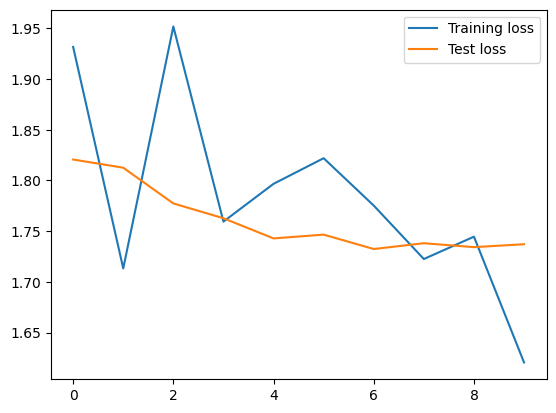

In [28]:
train_losses_np = [loss.detach().numpy() for loss in train_losses]
plt.plot(train_losses_np, label="Training loss")
plt.plot(test_losses, label= "Test loss")
plt.legend()

In [29]:
train_accuracy =[t/500 for t in train_correct ]
train_accuracy

[tensor(29.7040),
 tensor(35.4060),
 tensor(36.5960),
 tensor(37.3080),
 tensor(38.2980),
 tensor(38.6660),
 tensor(38.7980),
 tensor(39.3300),
 tensor(39.4460),
 tensor(39.6140)]

In [30]:
test_accuracy =[t/100 for t in test_correct ]
test_accuracy

[tensor(33.6200),
 tensor(34.3600),
 tensor(37.0400),
 tensor(37.6600),
 tensor(37.8800),
 tensor(36.8100),
 tensor(39.3100),
 tensor(38.9500),
 tensor(38.1100),
 tensor(37.6000)]

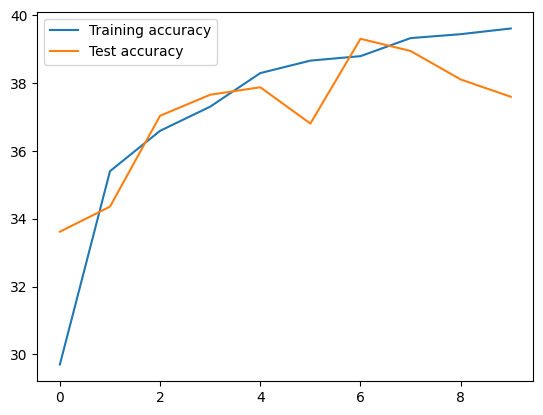

In [31]:
plt.plot(train_accuracy, label= "Training accuracy")
plt.plot(test_accuracy, label= "Test accuracy")
plt.legend()

In [32]:
# TODO: Implement the DataLoader for the test dataset

test_loader_all = DataLoader(cifar10_test, batch_size=10000, shuffle=False)

In [33]:
# Evaluation Loop for the Entire Test Dataset

with torch.no_grad():
    # TODO: Initialize a variable to track correct predictions
    correct = 0

    # TODO: Iterate over the test dataset
    for X_test, y_test in test_loader_all:

        # TODO: Reshape the input tensor
        # Hint: Flatten the images
        X_test = X_test.view(-1, 32*32*3)

        # TODO: Perform forward pass
        y_val = model(X_test)

        # TODO: Extract predictions
        predicted = torch.max(y_val, dim=1)[1]

        # TODO: Accumulate correct predictions
        correct += (predicted == y_test).sum()



In [34]:
100*correct.item()/len(cifar10_test)

37.6

In [35]:
confusion_matrix(predicted.view(-1),y_test.view(-1))

array([[243,  19,  50,   8,  25,   7,   2,   9,  52,  24],
       [ 42, 411,  35,  38,  20,  26,  29,  33,  58, 124],
       [130,  39, 347, 129, 204, 131, 117, 103,  43,  26],
       [  1,   4,   6,  48,   3,  20,   8,   9,   3,   4],
       [  9,  11,  44,  25, 185,  34,  48,  54,   6,   8],
       [ 95,  93, 183, 412, 194, 516, 165, 145,  98,  44],
       [ 27,  42, 163, 133, 191, 104, 525,  64,  12,  43],
       [ 62,  43,  65,  41, 100,  67,  29, 401,  18,  45],
       [204,  52,  52,  33,  22,  29,  16,  22, 447,  45],
       [187, 286,  55, 133,  56,  66,  61, 160, 263, 637]])

In [36]:
img = images[0].view(1, 3072)

# we are turning off the gradients
with torch.no_grad():
    # TODO: Perform a forward pass through the model
    model_prediction = model(img)

[0.04585418 0.01416399 0.33766812 0.07605684 0.08429932 0.27380908
 0.02990893 0.12097445 0.00988214 0.00738294]


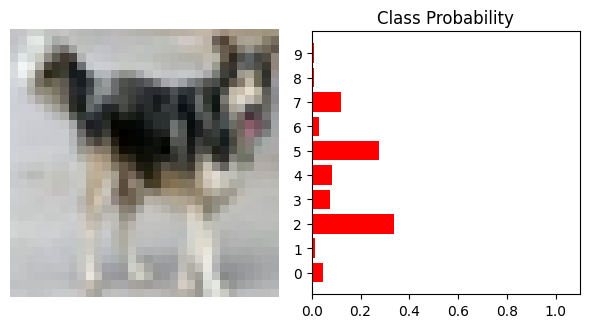

In [37]:
probabilities = F.softmax(model_prediction, dim=1).detach().cpu().numpy().squeeze()

print(probabilities)

fig, (ax1, ax2) = plt.subplots(figsize=(6,8), ncols=2)
img = img.view(3, 32, 32)
ax1.imshow(img.permute(1, 2, 0).detach().cpu().numpy().squeeze(), cmap='inferno')
ax1.axis('off')
ax2.barh(np.arange(10), probabilities, color='r' )
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(np.arange(10))
ax2.set_title('Class Probability')
ax2.set_xlim(0, 1.1)

plt.tight_layout()

In [38]:
test_load_all = DataLoader(cifar10_test, batch_size=64, shuffle=False)

In [39]:
# Extract a single batch from the test dataset
images, labels = next(iter(test_load_all))

with torch.no_grad():
    # TODO: Assign images and labels to variables (no device transfer in this version)
    # images, labels = ____________________, ____________________

    # TODO: Reshape images for model input
    # Hint: Flatten the images to match the input size
    preds = model(images.view(-1, 32*32*3))

# TODO: Convert images to numpy for visualization
# Hint: Use .cpu() and .numpy()
images_np = [i.mean(dim=0).cpu().numpy() for i in images]

# TODO: Access class names
# Hint: Use the dataset attribute
class_names = cifar10_test.classes


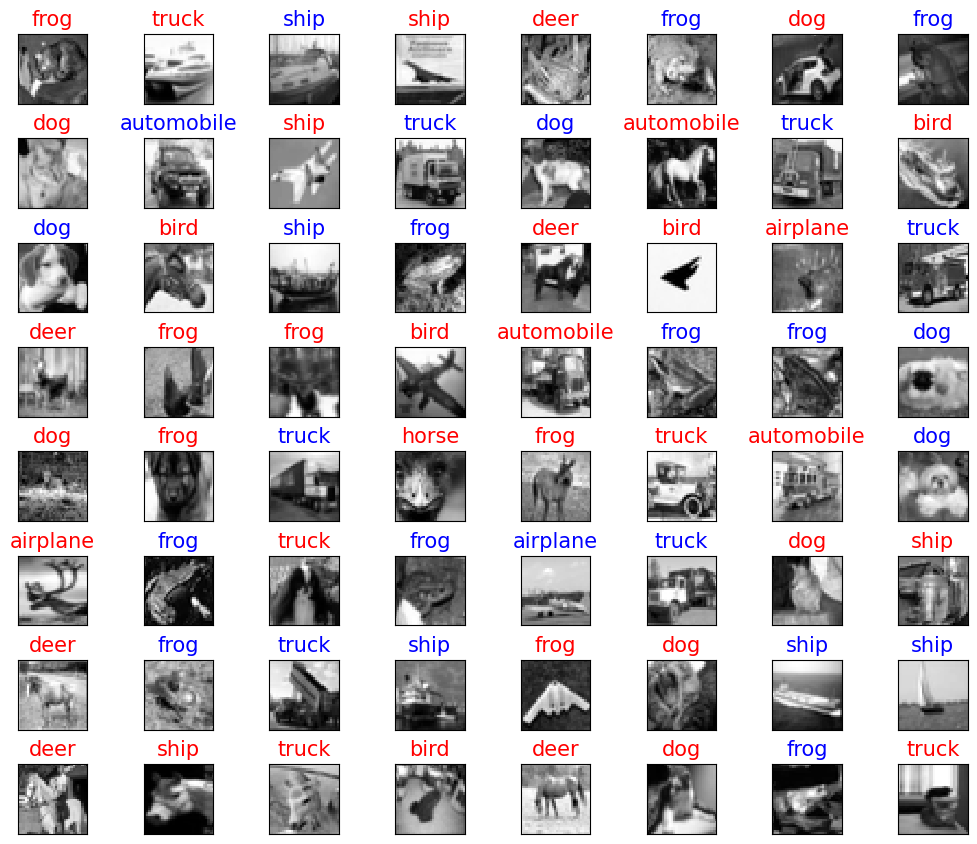

In [40]:
fig = plt.figure(figsize=(10, 8))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.5, wspace=0.05)

for i in range(64):
    ax = fig.add_subplot(8, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(images_np[i], cmap='gray', interpolation='nearest')
    color = "blue" if labels[i] == torch.max(preds[i], 0)[1] else "red"
    plt.title(class_names[torch.max(preds[i], 0)[1]], color=color, fontsize=15)